Tutorial source:
https://qiskit-community.github.io/qiskit-finance/tutorials/09_credit_risk_analysis.html

In [33]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumRegister, QuantumCircuit
from qiskit.circuit.library import IntegerComparator
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem
from qiskit_aer.primitives import Sampler

# Comment (from Desi Miteva Nikolova): Run the below commands if you do not have qiskit, and the rest of the qiskit libraries below installed.
# !pip install qiskit
# !pip install qiskit-algorithms
# !pip install qiskit-aer
# !pip install qiskit-finance

Problem Definition - set the problem parameters:

In [34]:
# set problem parameters
n_z = 2
z_max = 2
z_values = np.linspace(-z_max, z_max, 2**n_z)
p_zeros = [0.15, 0.25]
rhos = [0.1, 0.05]
lgd = [1, 2]
K = len(p_zeros)
alpha = 0.05

Uncertainty Model

In [35]:
from qiskit_finance.circuit.library import GaussianConditionalIndependenceModel as GCI
u = GCI(n_z, z_max, p_zeros, rhos)

In [36]:
u.draw()

┌───────┐
q_0: ┤0      ├
     │       │
q_1: ┤1      ├
     │  P(X) │
q_2: ┤2      ├
     │       │
q_3: ┤3      ├
     └───────┘

In [37]:
u_measure = u.measure_all(inplace=False)
sampler = Sampler()
job = sampler.run(u_measure)
binary_probabilities = job.result().quasi_dists[0].binary_probabilities()

In [38]:
# analyze uncertainty circuit and determine exact solutions
p_z = np.zeros(2**n_z)
p_default = np.zeros(K)
values = []
probabilities = []
num_qubits = u.num_qubits

for i, prob in binary_probabilities.items():
    # extract value of Z and corresponding probability
    i_normal = int(i[-n_z:], 2)
    p_z[i_normal] += prob

    # determine overall default probability for k
    loss = 0
    for k in range(K):
        if i[K - k - 1] == "1":
            p_default[k] += prob
            loss += lgd[k]

    values += [loss]
    probabilities += [prob]


values = np.array(values)
probabilities = np.array(probabilities)

expected_loss = np.dot(values, probabilities)
losses = np.sort(np.unique(values))
pdf = np.zeros(len(losses))
for i, v in enumerate(losses):
    pdf[i] += sum(probabilities[values == v])
cdf = np.cumsum(pdf)

i_var = np.argmax(cdf >= 1 - alpha)
exact_var = losses[i_var]
exact_cvar = np.dot(pdf[(i_var + 1) :], losses[(i_var + 1) :]) / sum(pdf[(i_var + 1) :])

In [39]:
print("Expected Loss E[L]:                %.4f" % expected_loss)
print("Value at Risk VaR[L]:              %.4f" % exact_var)
print("P[L <= VaR[L]]:                    %.4f" % cdf[exact_var])
print("Conditional Value at Risk CVaR[L]: %.4f" % exact_cvar)

Expected Loss E[L]:                0.6445
Value at Risk VaR[L]:              2.0000
P[L <= VaR[L]]:                    0.9600
Conditional Value at Risk CVaR[L]: 3.0000


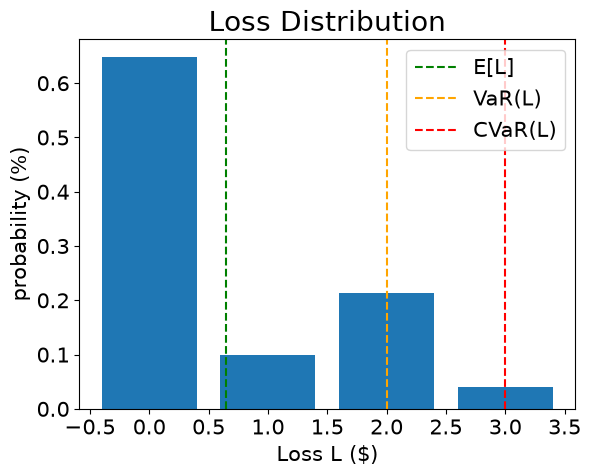

In [40]:
# plot loss PDF, expected loss, var, and cvar
plt.bar(losses, pdf)
plt.axvline(expected_loss, color="green", linestyle="--", label="E[L]")
plt.axvline(exact_var, color="orange", linestyle="--", label="VaR(L)")
plt.axvline(exact_cvar, color="red", linestyle="--", label="CVaR(L)")
plt.legend(fontsize=15)
plt.xlabel("Loss L ($)", size=15)
plt.ylabel("probability (%)", size=15)
plt.title("Loss Distribution", size=20)
plt.xticks(size=15)
plt.yticks(size=15)
plt.show()

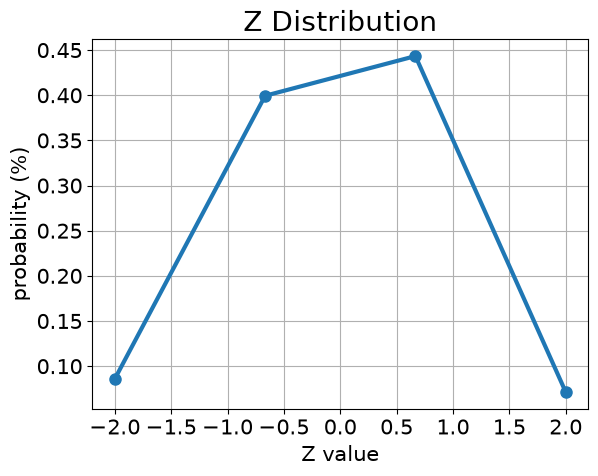

In [41]:
# plot results for Z
plt.plot(z_values, p_z, "o-", linewidth=3, markersize=8)
plt.grid()
plt.xlabel("Z value", size=15)
plt.ylabel("probability (%)", size=15)
plt.title("Z Distribution", size=20)
plt.xticks(size=15)
plt.yticks(size=15)
plt.show()

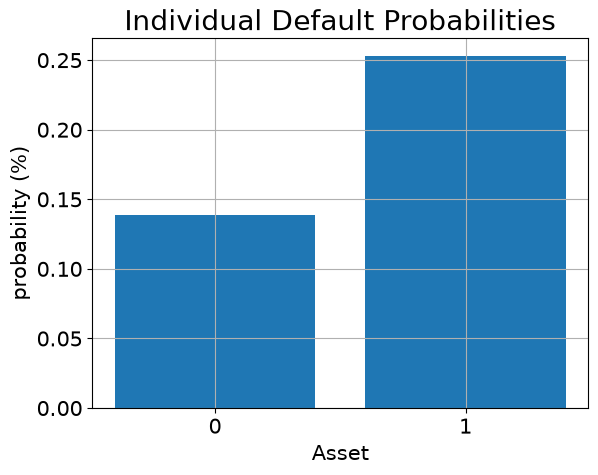

In [42]:
# plot results for default probabilities
plt.bar(range(K), p_default)
plt.xlabel("Asset", size=15)
plt.ylabel("probability (%)", size=15)
plt.title("Individual Default Probabilities", size=20)
plt.xticks(range(K), size=15)
plt.yticks(size=15)
plt.grid()
plt.show()

Expected Loss

In [43]:
# add Z qubits with weight/loss 0
from qiskit.circuit.library import WeightedAdder
agg = WeightedAdder(n_z + K, [0] * n_z + lgd)

In [44]:
from qiskit.circuit.library import LinearAmplitudeFunction

# define linear objective function
breakpoints = [0]
slopes = [1]
offsets = [0]
f_min = 0
f_max = sum(lgd)
c_approx = 0.25

objective = LinearAmplitudeFunction(
    agg.num_sum_qubits,
    slope=slopes,
    offset=offsets,
    # max value that can be reached by the qubit register (will not always be reached)
    domain=(0, 2**agg.num_sum_qubits - 1),
    image=(f_min, f_max),
    rescaling_factor=c_approx,
    breakpoints=breakpoints,
)

C:\Users\user\AppData\Local\Temp\ipykernel_9928\3038495397.py:11: DeprecationWarning: The class ``qiskit.circuit.library.arithmetic.linear_amplitude_function.LinearAmplitudeFunction`` is deprecated as of Qiskit 2.2. It will be removed in Qiskit 3.0. Use the class qiskit.circuit.library.LinearAmplitudeFunctionGate instead.
  objective = LinearAmplitudeFunction(


In [45]:
# define the registers for convenience and readability
qr_state = QuantumRegister(u.num_qubits, "state")
qr_sum = QuantumRegister(agg.num_sum_qubits, "sum")
qr_carry = QuantumRegister(agg.num_carry_qubits, "carry")
qr_obj = QuantumRegister(1, "objective")

# define the circuit
state_preparation = QuantumCircuit(qr_state, qr_obj, qr_sum, qr_carry, name="A")

# load the random variable
state_preparation.append(u.to_gate(), qr_state)

# aggregate
state_preparation.append(agg.to_gate(), qr_state[:] + qr_sum[:] + qr_carry[:])

# linear objective function
state_preparation.append(objective.to_gate(), qr_sum[:] + qr_obj[:])

# uncompute aggregation
state_preparation.append(agg.to_gate().inverse(), qr_state[:] + qr_sum[:] + qr_carry[:])

# draw the circuit
state_preparation.draw()

┌───────┐┌────────┐      ┌───────────┐
  state_0: ┤0      ├┤0       ├──────┤0          ├
           │       ││        │      │           │
  state_1: ┤1      ├┤1       ├──────┤1          ├
           │  P(X) ││        │      │           │
  state_2: ┤2      ├┤2       ├──────┤2          ├
           │       ││        │      │           │
  state_3: ┤3      ├┤3       ├──────┤3          ├
           └───────┘│  adder │┌────┐│  adder_dg │
objective: ─────────┤        ├┤2   ├┤           ├
                    │        ││    ││           │
    sum_0: ─────────┤4       ├┤0 F ├┤4          ├
                    │        ││    ││           │
    sum_1: ─────────┤5       ├┤1   ├┤5          ├
                    │        │└────┘│           │
    carry: ─────────┤6       ├──────┤6          ├
                    └────────┘      └───────────┘

In [46]:
state_preparation_measure = state_preparation.measure_all(inplace=False)
sampler = Sampler()
job = sampler.run(state_preparation_measure)
binary_probabilities = job.result().quasi_dists[0].binary_probabilities()

In [47]:
# evaluate the result
value = 0
for i, prob in binary_probabilities.items():
    if prob > 1e-6 and i[-(len(qr_state) + 1) :][0] == "1":
        value += prob

print("Exact Expected Loss:   %.4f" % expected_loss)
print("Exact Operator Value:  %.4f" % value)
print("Mapped Operator value: %.4f" % objective.post_processing(value))

Exact Expected Loss:   0.6445
Exact Operator Value:  0.3525
Mapped Operator value: 0.3735


In [48]:
# set target precision and confidence level
epsilon = 0.01
alpha = 0.05

problem = EstimationProblem(
    state_preparation=state_preparation,
    objective_qubits=[len(qr_state) - 1],  # Use index of last qubit instead of length
    post_processing=objective.post_processing,
)

# construct amplitude estimation with improved settings
ae = IterativeAmplitudeEstimation(
    epsilon_target=epsilon, 
    alpha=alpha, 
    sampler=Sampler(run_options={"shots": 1000, "seed": 75})  # Changed: Increased shots from 100 to 1000 for better accuracy
)

# Comment (from Desi Miteva Nikolova): The algorithms from above does not complete (exit with success). 
# Add error handling to catch and display specific issues
try:
    result = ae.estimate(problem)
    
    # print results
    conf_int = np.array(result.confidence_interval_processed)
    print("Estimated value:\t%.4f" % result.estimation_processed)
    print("Confidence interval: \t[%.4f, %.4f]" % tuple(conf_int))
    
except Exception as e:
    print(f"Error occurred: {type(e).__name__}")
    print(f"Error message: {str(e)}")
    # This will help identify the specific issue with your circuit or configuration

# print results
#conf_int = np.array(result.confidence_interval_processed)
#print("Exact value:    \t%.4f" % expected_loss)
#print("Estimated value:\t%.4f" % result.estimation_processed)
#print("Confidence interval: \t[%.4f, %.4f]" % tuple(conf_int))

Error occurred: AlgorithmError
Error message: 'The job was not completed successfully. '


Cumulative Distribution Function

In [49]:
# set x value to estimate the CDF
x_eval = 2

comparator = IntegerComparator(agg.num_sum_qubits, x_eval + 1, geq=False)
comparator.draw()

┌──────────────┐
state_0: ┤0             ├
         │              │
state_1: ┤1             ├
         │  circuit-253 │
compare: ┤2             ├
         │              │
    a30: ┤3             ├
         └──────────────┘

In [50]:
def get_cdf_circuit(x_eval):
    # define the registers for convenience and readability
    qr_state = QuantumRegister(u.num_qubits, "state")
    qr_sum = QuantumRegister(agg.num_sum_qubits, "sum")
    qr_carry = QuantumRegister(agg.num_carry_qubits, "carry")
    qr_obj = QuantumRegister(1, "objective")
    qr_compare = QuantumRegister(1, "compare")

    # define the circuit
    state_preparation = QuantumCircuit(qr_state, qr_obj, qr_sum, qr_carry, name="A")

    # load the random variable
    state_preparation.append(u, qr_state)

    # aggregate
    state_preparation.append(agg, qr_state[:] + qr_sum[:] + qr_carry[:])

    # comparator objective function
    comparator = IntegerComparator(agg.num_sum_qubits, x_eval + 1, geq=False)
    state_preparation.append(comparator, qr_sum[:] + qr_obj[:] + qr_carry[:])

    # uncompute aggregation
    state_preparation.append(agg.inverse(), qr_state[:] + qr_sum[:] + qr_carry[:])

    return state_preparation


state_preparation = get_cdf_circuit(x_eval)

In [51]:
state_preparation.draw()

┌───────┐┌────────┐        ┌───────────┐
  state_0: ┤0      ├┤0       ├────────┤0          ├
           │       ││        │        │           │
  state_1: ┤1      ├┤1       ├────────┤1          ├
           │  P(X) ││        │        │           │
  state_2: ┤2      ├┤2       ├────────┤2          ├
           │       ││        │        │           │
  state_3: ┤3      ├┤3       ├────────┤3          ├
           └───────┘│  adder │┌──────┐│  adder_dg │
objective: ─────────┤        ├┤2     ├┤           ├
                    │        ││      ││           │
    sum_0: ─────────┤4       ├┤0     ├┤4          ├
                    │        ││  cmp ││           │
    sum_1: ─────────┤5       ├┤1     ├┤5          ├
                    │        ││      ││           │
    carry: ─────────┤6       ├┤3     ├┤6          ├
                    └────────┘└──────┘└───────────┘

In [52]:
state_preparation_measure = state_preparation.measure_all(inplace=False)
sampler = Sampler()
job = sampler.run(state_preparation_measure)
binary_probabilities = job.result().quasi_dists[0].binary_probabilities()

In [53]:
# evaluate the result
var_prob = 0
for i, prob in binary_probabilities.items():
    if prob > 1e-6 and i[-(len(qr_state) + 1) :][0] == "1":
        var_prob += prob

print("Operator CDF(%s)" % x_eval + " = %.4f" % var_prob)
print("Exact    CDF(%s)" % x_eval + " = %.4f" % cdf[x_eval])

Operator CDF(2) = 0.9609
Exact    CDF(2) = 0.9600


In [54]:
# Comment (from Desi Miteva Nikolova) - the below code is not setup correctly in the tutorial so the debugging
# helps to suggest more precisely where the problem might be.

# set target precision and confidence level
epsilon = 0.01
alpha = 0.05

# Add validation before creating the problem
print("Debugging Information:")
print(f"State preparation circuit: {state_preparation}")
print(f"Number of qubits in qr_state: {len(qr_state)}")
print(f"Objective qubit index: {len(qr_state)-1}")

# Verify the state_preparation circuit is valid
try:
    # Draw the circuit to verify it's properly constructed
    print("\nState preparation circuit:")
    print(state_preparation.draw())
except Exception as e:
    print(f"Error with state_preparation circuit: {e}")

# Create the estimation problem with error handling
try:
    problem = EstimationProblem(
        state_preparation=state_preparation, 
        objective_qubits=[len(qr_state)-1]
    )
    print("EstimationProblem created successfully")
except Exception as e:
    print(f"Error creating EstimationProblem: {e}")
    raise

# construct amplitude estimation with adjusted parameters
# Increased shots for better stability and removed seed for testing
ae_cdf = IterativeAmplitudeEstimation(
    epsilon_target=epsilon, 
    alpha=alpha, 
    sampler=Sampler(run_options={"shots": 1000})  # Increased shots, removed seed
)

# Run estimation with comprehensive error handling
try:
    print("\nRunning amplitude estimation...")
    result_cdf = ae_cdf.estimate(problem)
    
    # print results
    conf_int = np.array(result_cdf.confidence_interval)
    print("\n=== Results ===")
    print("Exact value:    \t%.4f" % cdf[x_eval])
    print("Estimated value:\t%.4f" % result_cdf.estimation)
    print("Confidence interval: \t[%.4f, %.4f]" % tuple(conf_int))
    
except Exception as e:
    print(f"\nError during estimation: {e}")
    print("\nTroubleshooting steps:")
    print("1. Verify state_preparation circuit is valid and properly constructed")
    print("2. Check that objective_qubits index is correct and within range")
    print("3. Ensure all qubits are properly initialized in the circuit")
    print("4. Try simplifying the circuit or using a different backend")
    print("5. Verify that qr_state is defined and has the expected number of qubits")

Debugging Information:
State preparation circuit:            ┌───────┐┌────────┐        ┌───────────┐
  state_0: ┤0      ├┤0       ├────────┤0          ├
           │       ││        │        │           │
  state_1: ┤1      ├┤1       ├────────┤1          ├
           │  P(X) ││        │        │           │
  state_2: ┤2      ├┤2       ├────────┤2          ├
           │       ││        │        │           │
  state_3: ┤3      ├┤3       ├────────┤3          ├
           └───────┘│  adder │┌──────┐│  adder_dg │
objective: ─────────┤        ├┤2     ├┤           ├
                    │        ││      ││           │
    sum_0: ─────────┤4       ├┤0     ├┤4          ├
                    │        ││  cmp ││           │
    sum_1: ─────────┤5       ├┤1     ├┤5          ├
                    │        ││      ││           │
    carry: ─────────┤6       ├┤3     ├┤6          ├
                    └────────┘└──────┘└───────────┘
Number of qubits in qr_state: 4
Objective qubit index: 3

State pr

Value at Risk

In [55]:
def run_ae_for_cdf(x_eval, epsilon=0.01, alpha=0.05):

    # construct amplitude estimation
    state_preparation = get_cdf_circuit(x_eval)
    problem = EstimationProblem(
        state_preparation=state_preparation, objective_qubits=[len(qr_state)]
    )
    ae_var = IterativeAmplitudeEstimation(
        epsilon_target=epsilon, alpha=alpha, sampler=Sampler(run_options={"shots": 100, "seed": 75})
    )
    result_var = ae_var.estimate(problem)

    return result_var.estimation

In [56]:
def bisection_search(
    objective, target_value, low_level, high_level, low_value=None, high_value=None
):
    """
    Determines the smallest level such that the objective value is still larger than the target
    :param objective: objective function
    :param target: target value
    :param low_level: lowest level to be considered
    :param high_level: highest level to be considered
    :param low_value: value of lowest level (will be evaluated if set to None)
    :param high_value: value of highest level (will be evaluated if set to None)
    :return: dictionary with level, value, num_eval
    """

    # check whether low and high values are given and evaluated them otherwise
    print("--------------------------------------------------------------------")
    print("start bisection search for target value %.3f" % target_value)
    print("--------------------------------------------------------------------")
    num_eval = 0
    if low_value is None:
        low_value = objective(low_level)
        num_eval += 1
    if high_value is None:
        high_value = objective(high_level)
        num_eval += 1

    # check if low_value already satisfies the condition
    if low_value > target_value:
        return {
            "level": low_level,
            "value": low_value,
            "num_eval": num_eval,
            "comment": "returned low value",
        }
    elif low_value == target_value:
        return {"level": low_level, "value": low_value, "num_eval": num_eval, "comment": "success"}

    # check if high_value is above target
    if high_value < target_value:
        return {
            "level": high_level,
            "value": high_value,
            "num_eval": num_eval,
            "comment": "returned low value",
        }
    elif high_value == target_value:
        return {
            "level": high_level,
            "value": high_value,
            "num_eval": num_eval,
            "comment": "success",
        }

    # perform bisection search until
    print("low_level    low_value    level    value    high_level    high_value")
    print("--------------------------------------------------------------------")
    while high_level - low_level > 1:

        level = int(np.round((high_level + low_level) / 2.0))
        num_eval += 1
        value = objective(level)

        print(
            "%2d           %.3f        %2d       %.3f    %2d            %.3f"
            % (low_level, low_value, level, value, high_level, high_value)
        )

        if value >= target_value:
            high_level = level
            high_value = value
        else:
            low_level = level
            low_value = value

    # return high value after bisection search
    print("--------------------------------------------------------------------")
    print("finished bisection search")
    print("--------------------------------------------------------------------")
    return {"level": high_level, "value": high_value, "num_eval": num_eval, "comment": "success"}

In [57]:
# Comment (from Desi Miteva Nikolova) - the below code does not work in the original tutorial as well :)...
# Debugging code is included below but the source of the error is not identified and the error is not remedied. 

# Add error handling and debugging to the bisection search
import traceback

# Test the objective function first with sample values
try:
    test_value = (min(losses) + max(losses)) / 2
    print(f"Testing objective function with value: {test_value}")
    test_result = run_ae_for_cdf(test_value)
    print(f"Test result: {test_result}")
except Exception as e:
    print(f"Error in objective function: {e}")
    traceback.print_exc()

# Define objective with error handling
def objective(x):
    try:
        result = run_ae_for_cdf(x)
        print(f"Objective at x={x}: {result}")  # Debug output
        return result
    except Exception as e:
        print(f"Error at x={x}: {e}")
        raise

# Add validation for parameters
print(f"Alpha: {alpha}")
print(f"Target value (1-alpha): {1 - alpha}")
print(f"Search bounds: [{min(losses) - 1}, {max(losses)}]")

# Run bisection search with error handling
try:
    bisection_result = bisection_search(
        objective, 
        1 - alpha, 
        min(losses) - 1, 
        max(losses), 
        low_value=0, 
        high_value=1
    )
    var = bisection_result["level"]
    print(f"VaR calculated successfully: {var}")
except Exception as e:
    print(f"Bisection search failed: {e}")
    traceback.print_exc()
    # Optionally set a fallback value or re-raise
    var = None

Testing objective function with value: 1.5
Error in objective function: 'The job was not completed successfully. '
Alpha: 0.05
Target value (1-alpha): 0.95
Search bounds: [-1, 3]
--------------------------------------------------------------------
start bisection search for target value 0.950
--------------------------------------------------------------------
low_level    low_value    level    value    high_level    high_value
--------------------------------------------------------------------
Error at x=1: 'The job was not completed successfully. '
Bisection search failed: 'The job was not completed successfully. '


C:\Users\user\AppData\Local\Temp\ipykernel_9928\3499977338.py:11: DeprecationWarning: Sampler has been deprecated as of Aer 0.15, please use SamplerV2 instead.
  test_result = run_ae_for_cdf(test_value)
Traceback (most recent call last):
  File "C:\Users\user\anaconda3\Lib\site-packages\qiskit_algorithms\amplitude_estimators\iae.py", line 327, in estimate
    job = self._sampler.run([(circuit,)])
  File "C:\Users\user\anaconda3\Lib\site-packages\qiskit\primitives\base\base_sampler.py", line 177, in run
    circuits, parameter_values = _validate_sampler_args(circuits, parameter_values)
                                 ~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\user\anaconda3\Lib\site-packages\qiskit\primitives\base\validation_v1.py", line 83, in _validate_sampler_args
    circuits = _validate_circuits(circuits, requires_measure=True)
  File "C:\Users\user\anaconda3\Lib\site-packages\qiskit\primitives\base\validation_v1.py", line 127, in _validate_circuits
    ra

Conditional Value at Risk

In [58]:
# Comment (from Desi Miteva Nikolova) - the below code below from the original tutorial :)...

#define linear objective
#breakpoints = [0, var]
#slopes = [0, 1]
#offsets = [0, 0]  # subtract VaR and add it later to the estimate
#f_min = 0
#f_max = 3 - var
#c_approx = 0.25

#cvar_objective = LinearAmplitudeFunction(
    #agg.num_sum_qubits,
    #slopes,
    #offsets,
    #domain=(0, 2**agg.num_sum_qubits - 1),
    #image=(f_min, f_max),
    #rescaling_factor=c_approx,
   # breakpoints=breakpoints,
#)

#cvar_objective.draw()

In [59]:
#...